# Predicción de mapas de calor (LST) en Tlaxcala y Puebla con cómputo paralelo

**Objetivo:** predecir la temperatura superficial (LST, °C) de cada pixel de 1 km en el mes *t* a partir de los mapas de calor de los meses anteriores (*t−1, t−2, t−3, t−12*), el NDVI del mes anterior, la altitud, la ubicación y el mes.

**Datos:** MODIS Terra (MOD11A2 y MOD13A3), 2015–2024, 120 mapas mensuales; descargados con `01_descarga_MODIS_GEE.js`.

**Paralelismo (multiprocessing, sin joblib ni n_jobs):**
1. Construcción de la tabla: la imagen se parte en bloques de filas, uno por proceso (paralelismo de datos).
2. Búsqueda de hiperparámetros de KNN, RF y SVR: cada combinación es una tarea (reparto estático vs. dinámico).

In [3]:
import os
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v] = "1"

import multiprocessing as mp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import datos

RUTA_LST = os.environ.get("RUTA_LST", "LST_mensual.tif")
RUTA_NDVI = os.environ.get("RUTA_NDVI", "NDVI_mensual.tif")
RUTA_ALT = os.environ.get("RUTA_ALT", "ALTITUD.tif")
ANIO_PRUEBA = 2024
N_MAX_ENTRENAMIENTO = int(os.environ.get("N_MAX", 40000))
NUCLEOS = mp.cpu_count()
LISTA_PROCESOS = [p for p in [1, 2, 4, 8, 16] if p <= NUCLEOS]

os.makedirs("resultados", exist_ok=True)
os.makedirs("figuras", exist_ok=True)
COLORES = {"KNN": "#2a78d6", "RF": "#eb6834", "SVR": "#1baf7a"}
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
print("Núcleos:", NUCLEOS, "| Procesos a medir:", LISTA_PROCESOS)

%pip install rasterio

Núcleos: 8 | Procesos a medir: [1, 2, 4, 8]
   ---------------------------------------- 0.0/31.5 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.5 MB ? eta -:--:--
    --------------------------------------- 0.8/31.5 MB 4.8 MB/s eta 0:00:07
   --- ------------------------------------ 2.6/31.5 MB 7.1 MB/s eta 0:00:05
   ---- ----------------------------------- 3.9/31.5 MB 6.9 MB/s eta 0:00:04
   ------ --------------------------------- 5.2/31.5 MB 7.9 MB/s eta 0:00:04
   ---------- ----------------------------- 8.1/31.5 MB 9.1 MB/s eta 0:00:03
   ------------ --------------------------- 10.0/31.5 MB 9.2 MB/s eta 0:00:03
   --------------- ------------------------ 12.1/31.5 MB 8.3 MB/s eta 0:00:03
   ----------------- ---------------------- 14.2/31.5 MB 8.7 MB/s eta 0:00:03
   --------------------- ------------------ 16.8/31.5 MB 9.0 MB/s eta 0:00:02
   ---------------------- ----------------- 18.1/31.5 MB 9.2 MB/s eta 0:00:02
   -------------------------- -----------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Lectura de los mapas mensuales

Mapas: 120 meses de 329 x 261 pixeles


C:\Users\CHECA\AppData\Local\Temp\ipykernel_16388\1441920089.py:6: RuntimeWarning: Mean of empty slice
  im = axes[0].imshow(np.nanmean(lst[-12:], axis=0), cmap="inferno",


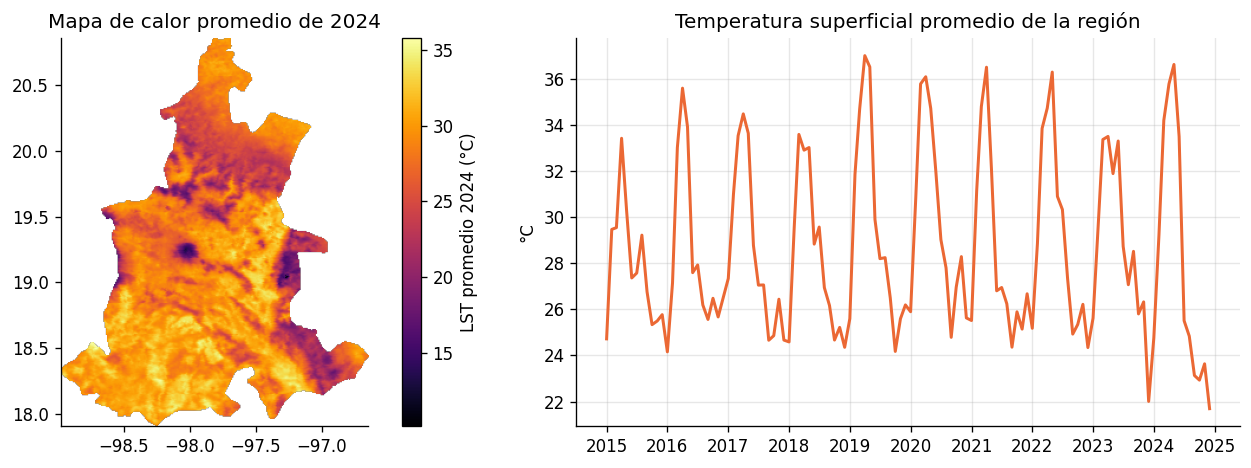

In [4]:
mapas = datos.leer_mapas(RUTA_LST, RUTA_NDVI, RUTA_ALT)
lst, ndvi, alt, lat, lon = mapas

# Mapa de calor de ejemplo y temperatura promedio de la región por mes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
im = axes[0].imshow(np.nanmean(lst[-12:], axis=0), cmap="inferno",
                    extent=[lon[0], lon[-1], lat[-1], lat[0]])
fig.colorbar(im, ax=axes[0], label="LST promedio 2024 (°C)")
axes[0].set_title("Mapa de calor promedio de 2024"); axes[0].grid(False)
serie = np.nanmean(lst.reshape(lst.shape[0], -1), axis=1)
meses = pd.date_range(f"{datos.ANIO_INICIO}-01-01", periods=len(serie), freq="MS")
axes[1].plot(meses, serie, color="#eb6834", lw=1.8)
axes[1].set_title("Temperatura superficial promedio de la región"); axes[1].set_ylabel("°C")
fig.tight_layout(); fig.savefig("figuras/mapas_y_serie.png", dpi=200); plt.show()

## 2. Construcción de la tabla en paralelo (paralelismo de datos)

Cada fila de la tabla es un pixel en un mes. Las filas de la imagen se reparten en bloques con `nivelar()` y cada proceso arma las variables de su bloque. Se mide el tiempo con 1, 2, 4… procesos.

In [5]:
tiempos_tabla = {}
for p in LISTA_PROCESOS:
    df, t = datos.construir_variables(mapas, procesos=p)
    tiempos_tabla[p] = t
    print(f"{p:>2} procesos: {t:7.2f} s  ->  {len(df):,} filas")

t1 = tiempos_tabla[1]
tabla_tiempos = pd.DataFrame([{"procesos": p, "tiempo_s": t, "speedup": t1 / t, "eficiencia": t1 / t / p}
                              for p, t in tiempos_tabla.items()])
tabla_tiempos.to_csv("resultados/desempeno_construccion_tabla.csv", index=False)
tabla_tiempos.round(3)

 1 procesos:   36.28 s  ->  4,429,724 filas
 2 procesos:   27.23 s  ->  4,429,724 filas
 4 procesos:   27.02 s  ->  4,429,724 filas
 8 procesos:   40.93 s  ->  4,429,724 filas


,procesos,tiempo_s,speedup,eficiencia
0,1,36.277,1.000,1.000
1,2,27.230,1.332,0.666
2,4,27.019,1.343,0.336
3,8,40.929,0.886,0.111


In [6]:
# Descripción de los datos
resumen_datos = pd.DataFrame({"dato": ["Filas (pixel-mes)", "Pixeles con datos", "Meses", "Años"],
    "valor": [len(df), df.groupby(["fila", "col"]).ngroups, df[["anio", "mes"]].drop_duplicates().shape[0],
              f"{df['anio'].min()}–{df['anio'].max()}"]})
desc = df[["LST"] + datos.COLUMNAS_X[:6]].describe().T[["mean", "std", "min", "max"]].round(3)
resumen_datos.to_csv("resultados/resumen_datos.csv", index=False)
desc.to_csv("resultados/descripcion_variables.csv")
display(resumen_datos)
desc

,dato,valor
0,Filas (pixel-mes),4429724
1,Pixeles con datos,41050
2,Meses,108
3,Años,2016–2024


,mean,std,min,max
LST,28.777,6.078,0.143,51.177
LST_t1,28.813,6.050,0.143,51.177
LST_t2,28.830,6.044,0.143,51.177
LST_t3,28.851,6.029,0.143,51.177
LST_t12,28.768,5.907,0.143,51.177
NDVI_t1,0.525,0.207,-0.200,0.965
ALTITUD,1821.903,769.810,41.000,5322.000


## 3. Partición

- **Prueba:** los 12 mapas de 2024 (el modelo predice un año que nunca vio).
- **Entrenamiento y validación:** años anteriores, al azar (80% / 20%).

In [7]:
ent, val, prueba = datos.particionar(df, anio_prueba=ANIO_PRUEBA, n_max_entrenamiento=N_MAX_ENTRENAMIENTO)
X_ent, y_ent = ent[datos.COLUMNAS_X].to_numpy(), ent[datos.COLUMNA_Y].to_numpy()
X_val, y_val = val[datos.COLUMNAS_X].to_numpy(), val[datos.COLUMNA_Y].to_numpy()
X_pru, y_pru = prueba[datos.COLUMNAS_X].to_numpy(), prueba[datos.COLUMNA_Y].to_numpy()
datos_modelo = (X_ent, y_ent, X_val, y_val)

Entrenamiento: 40,000 | Validación: 50,000 | Prueba (2024): 491,336
